# Clasificador Bayesiano para el dataset *digits* de Scikit Learn

## Integrantes
- Isabella Arrieta 
- Natalia Carpintero
- Paula Núñez

El clasificador bayesiano ingenuo estima, para cada clase $y$, una cantidad proporcional a la probabilidad a posteriori:

$P(y/X) \propto P(y)\,P(x_0/y)\,P(x_1/y)\cdots P(x_n/y)$

y asigna a $X$ la clase con el mayor valor. La forma en que se calcula cada $P(x_i/y)$ depende de la distribución que sigan los datos (Bernoulli, Multinomial, Complementario, Categórico o Gaussiano).

Pasos de la solución:
1. Cargar y describir el dataset.
2. Dividir los datos en 80% para entrenamiento y 20% para prueba.
3. Analizar la distribución de los datos.
4. Comparar los tipos de clasificador bayesiano con K-fold = 4 y elegir el que mejor se adapte a los datos.
5. Aplicar el Suavizado de Laplace al clasificador elegido y analizar el efecto de $\alpha$ en los indicadores de desempeño.

## 1. Carga y descripción de los datos

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits

digits = load_digits()
X = digits.data
y = digits.target
print(X.shape)
print(y.shape)
print("Clases:", np.unique(y))
print("Valores que toman las características:", np.unique(X))

(1797, 64)
(1797,)
Clases: [0 1 2 3 4 5 6 7 8 9]
Valores que toman las características: [ 0.  1.  2.  3.  4.  5.  6.  7.  8.  9. 10. 11. 12. 13. 14. 15. 16.]


El dataset tiene 1797 imágenes de dígitos del 0 al 9, que son las clases **(y)**. Cada imagen tiene 8x8 = 64 píxeles, que son las características **(x)**.

Cada píxel indica cuántos puntos de tinta hay en un bloque de 4x4 de la imagen original de 32x32. Por eso toma valores enteros entre 0 (blanco) y 16 (negro).

## 2. División en entrenamiento (80%) y prueba (20%)

Se usa `stratify=y` para que cada clase quede en la misma proporción en ambos conjuntos.

`test_size=0.20` asigna el 20% de los datos a prueba y el 80% restante a entrenamiento, como pide el enunciado.

In [2]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = \
    train_test_split(X, y, test_size=0.20, random_state=4, stratify=y)
print(X_train.shape, y_train.shape)
print(X_test.shape, y_test.shape)

(1437, 64) (1437,)
(360, 64) (360,)


## 3. Distribución de los datos

Se calcula con qué frecuencia aparece cada valor (0 a 16) en los píxeles de entrenamiento: primero en todos los píxeles juntos (tabla y gráfica izquierda) y luego en un solo píxel, comparando tres dígitos (gráfica derecha).

Como ejemplo se usa el píxel 20 (fila 3, columna 5 de la imagen), porque en él se nota claramente que los valores cambian según el dígito. Los píxeles de los bordes no sirven para esto, porque casi siempre valen 0 (blanco) en todos los dígitos.

In [3]:
valores, conteos = np.unique(X_train, return_counts=True)
frecuencias = pd.DataFrame({'valor': valores.astype(int),
                            'frecuencia relativa': np.round(conteos / conteos.sum(), 3)})
frecuencias.T

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16
valor,0.000,1.000,2.000,3.000,4.000,5.000,6.000,7.000,8.00,9.000,10.000,11.000,12.000,13.00,14.000,15.000,16.000
frecuencia relativa,0.489,0.036,0.028,0.025,0.028,0.024,0.022,0.023,0.03,0.023,0.024,0.025,0.032,0.03,0.031,0.038,0.091


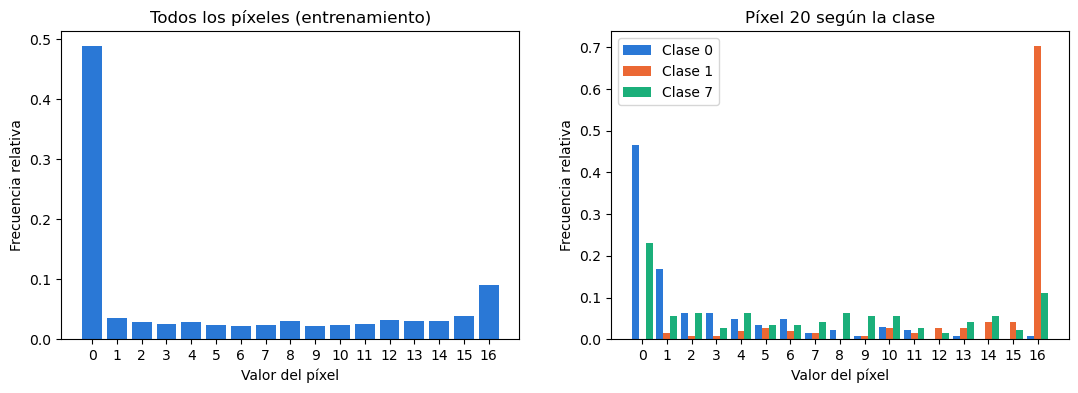

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))

ax[0].bar(valores, conteos / conteos.sum(), color='#2a78d6')
ax[0].set_title("Todos los píxeles (entrenamiento)")
ax[0].set_xlabel("Valor del píxel")
ax[0].set_ylabel("Frecuencia relativa")
ax[0].set_xticks(range(17))

pixel = 20
colores = {0: '#2a78d6', 1: '#eb6834', 7: '#1baf7a'}
ancho = 0.28
for i, clase in enumerate([0, 1, 7]):
    v = X_train[y_train == clase, pixel].astype(int)
    frec = np.bincount(v, minlength=17) / len(v)
    ax[1].bar(np.arange(17) + (i - 1) * ancho, frec, width=ancho,
              color=colores[clase], label=f"Clase {clase}")
ax[1].set_title(f"Píxel {pixel} según la clase")
ax[1].set_xlabel("Valor del píxel")
ax[1].set_ylabel("Frecuencia relativa")
ax[1].set_xticks(range(17))
ax[1].legend()
plt.show()

Observaciones:

* Los datos son **discretos**: cada píxel solo toma 17 valores enteros (0 a 16).
* La distribución de todos los píxeles juntos **no es normal**: casi la mitad de los valores son 0, hay otro pico en 16 y los valores intermedios son poco frecuentes.
* Un mismo píxel puede tener una distribución distinta en cada clase. Por ejemplo, en el píxel 20, la clase 0 se concentra en 0, la clase 1 en 16 y la clase 7 tiene dos picos (en 0 y en 16).

Por lo tanto, dada la clase $y$, cada píxel $x_i$ sigue una **distribución categórica** sobre los 17 valores posibles: 

$P(x_i = v / y) = p_{i,v,y}, \quad v \in \{0, 1, \dots, 16\}$

Cada probabilidad $p_{i,v,y}$ se estima contando cuántas veces aparece el valor $v$ en el píxel $x_i$ dentro de la clase $y$.

## 4. Comparación de clasificadores con K-fold = 4

Cada tipo de clasificador se evalúa con validación cruzada K-fold (k = 4) sobre los datos de entrenamiento: estos se dividen en 4 partes, se entrena con 3 y se valida con la restante, repitiendo el proceso 4 veces para que cada parte se use una vez como validación. Los datos de prueba se reservan para la evaluación final.

Indicadores (promedio de las 4 particiones):
* **accuracy**: proporción de imágenes bien clasificadas.
* **precision**: de las imágenes asignadas a un dígito, proporción que realmente eran ese dígito.
* **recall**: de las imágenes de un dígito, proporción que el clasificador reconoció.

La precision y el recall se promedian entre las 10 clases (`macro`).

Configuración:
* Todos los clasificadores, excepto el Gaussiano, usan $\alpha = 1$. El Gaussiano no tiene este parámetro.
* `CategoricalNB` usa `min_categories=17` para reconocer los 17 valores aunque alguno no aparezca en una partición.

In [5]:
from sklearn.model_selection import KFold, cross_validate
from sklearn.naive_bayes import GaussianNB, MultinomialNB, ComplementNB, BernoulliNB, CategoricalNB

kfold = KFold(n_splits=4, shuffle=True, random_state=4)
metricas = ['accuracy', 'precision_macro', 'recall_macro']

clasificadores = {
    'Gaussiano': GaussianNB(),
    'Bernoulli': BernoulliNB(alpha=1.0),
    'Multinomial': MultinomialNB(alpha=1.0),
    'Complementario': ComplementNB(alpha=1.0),
    'Categórico': CategoricalNB(alpha=1.0, min_categories=17),
}

resultados = []
for nombre, clf in clasificadores.items():
    cv = cross_validate(clf, X_train, y_train, cv=kfold, scoring=metricas)
    resultados.append({'Clasificador': nombre,
                       'accuracy': cv['test_accuracy'].mean(),
                       'precision': cv['test_precision_macro'].mean(),
                       'recall': cv['test_recall_macro'].mean()})

resultados = pd.DataFrame(resultados).sort_values('accuracy', ascending=False)
resultados.round(4)

,Clasificador,accuracy,precision,recall
4,Categórico,0.9116,0.9146,0.9164
2,Multinomial,0.8991,0.9065,0.9036
1,Bernoulli,0.8518,0.8547,0.8565
0,Gaussiano,0.8399,0.8633,0.8434
3,Complementario,0.8044,0.8299,0.8077


### Elección del clasificador

De acuerdo con la tabla anterior, el **Categórico** obtiene los mejores indicadores (accuracy 0.9116, precision 0.9146, recall 0.9164). Este resultado coincide con la distribución de los datos vista en la sección 3. De menor a mayor accuracy (entre paréntesis):

* **Complementario** (0.8044): está pensado para clases desbalanceadas, y aquí las 10 clases están balanceadas.
* **Gaussiano** (0.8399): supone datos continuos con distribución normal, pero los píxeles son discretos y pueden tener dos picos.
* **Bernoulli** (0.8518): solo usa 0 y 1, por lo que pierde la intensidad del trazo.
* **Multinomial** (0.8991): trabaja con conteos discretos, por eso queda segundo, pero no puede representar un píxel con dos picos.
* **Categórico** (0.9116): estima una probabilidad para cada uno de los 17 valores de cada píxel en cada clase, por lo que se ajusta a cualquier forma de distribución.

**Conclusión:** tanto la forma de los datos como los resultados de K-fold indican que los datos siguen una **distribución categórica**. El clasificador elegido es el **Bayesiano Ingenuo Categórico** (`CategoricalNB`).

## 5. Suavizado de Laplace

En el clasificador Categórico, la probabilidad de que el píxel $x_i$ tome el valor $v$ en la clase $y$ es:

$P(x_i = v / y) = \frac{N_{i,v,y} + \alpha}{N_y + 17\,\alpha}$

* $N_{i,v,y}$: número de imágenes de la clase $y$ en las que el píxel $x_i$ vale $v$.
* $N_y$: número de imágenes de la clase $y$.
* $17$: número de valores posibles de cada píxel.
* $\alpha$: parámetro de suavizado. Con $\alpha = 1$ se tiene el Suavizado de Laplace.

Sin suavizado ($\alpha = 0$), un valor que no apareció en el entrenamiento tiene probabilidad 0, y el producto completo de esa clase se vuelve 0. `CategoricalNB` exige $\alpha \geq 10^{-10}$, por lo que se usa ese valor para representar el caso sin suavizado.

### 5.1 Evaluación con los datos de prueba

Se entrena el clasificador Categórico con $\alpha = 1$ usando todos los datos de entrenamiento y se evalúa con los datos de prueba.

In [6]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, confusion_matrix

CategNB = CategoricalNB(alpha=1.0, min_categories=17)
CategNB.fit(X_train, y_train)
y_esperado = y_test
y_predicho = CategNB.predict(X_test)

print("accuracy :", round(accuracy_score(y_esperado, y_predicho), 4))
print("precision:", round(precision_score(y_esperado, y_predicho, average='macro'), 4))
print("recall   :", round(recall_score(y_esperado, y_predicho, average='macro'), 4))
print("Matriz de confusión:")
print(confusion_matrix(y_esperado, y_predicho))

accuracy : 0.9167
precision: 0.9246
recall   : 0.9165
Matriz de confusión:
[[36  0  0  0  0  0  0  0  0  0]
 [ 0 34  0  0  0  0  0  0  0  3]
 [ 0  0 35  0  0  0  0  0  0  0]
 [ 0  0  1 33  0  0  0  1  1  1]
 [ 0  1  0  0 33  0  0  1  1  0]
 [ 0  0  0  0  1 31  0  0  0  4]
 [ 0  2  0  0  1  0 33  0  0  0]
 [ 0  0  0  0  0  0  0 36  0  0]
 [ 0  4  1  0  0  0  0  2 26  2]
 [ 0  1  0  0  1  0  0  1  0 33]]


Los resultados en prueba (accuracy 0.9167, precision 0.9246, recall 0.9165) son similares a los de K-fold, por lo que el modelo generaliza bien.

En la matriz de confusión (filas: dígito real, columnas: dígito predicho), los dígitos 0, 2 y 7 se clasifican sin errores. Los errores más frecuentes son el 8 clasificado como 1 (4 veces), el 5 como 9 (4 veces) y el 1 como 9 (3 veces).

### 5.2 Efecto de $\alpha$ en los indicadores

Se evalúa el clasificador con valores de $\alpha$ entre $10^{-10}$ y $1000$, con K-fold = 4 y con los datos de prueba.

In [7]:
import warnings
from sklearn.exceptions import UndefinedMetricWarning
# con alpha grande algunos dígitos nunca se predicen y su precision queda indefinida (se toma como 0)
warnings.filterwarnings('ignore', category=UndefinedMetricWarning)

alphas = [1e-10, 0.001, 0.01, 0.1, 0.5, 1, 2, 5, 10, 50, 100, 1000]

efecto_alpha = []
for a in alphas:
    clf = CategoricalNB(alpha=a, min_categories=17)
    cv = cross_validate(clf, X_train, y_train, cv=kfold, scoring=metricas)
    clf.fit(X_train, y_train)
    y_predicho = clf.predict(X_test)
    efecto_alpha.append({'alpha': a,
                         'accuracy (K-fold)': cv['test_accuracy'].mean(),
                         'precision (K-fold)': cv['test_precision_macro'].mean(),
                         'recall (K-fold)': cv['test_recall_macro'].mean(),
                         'accuracy (prueba)': accuracy_score(y_test, y_predicho),
                         'precision (prueba)': precision_score(y_test, y_predicho, average='macro'),
                         'recall (prueba)': recall_score(y_test, y_predicho, average='macro')})

efecto_alpha = pd.DataFrame(efecto_alpha)
tabla = efecto_alpha.round(4)
tabla['alpha'] = [str(a) for a in alphas]
tabla

,alpha,accuracy (K-fold),precision (K-fold),recall (K-fold),accuracy (prueba),precision (prueba),recall (prueba)
0,1e-10,0.8330,0.8516,0.8368,0.8667,0.8757,0.8674
1,0.001,0.8928,0.9002,0.8976,0.9194,0.9226,0.9196
2,0.01,0.9060,0.9121,0.9110,0.9194,0.9228,0.9195
3,0.1,0.9088,0.9123,0.9133,0.9111,0.9168,0.9110
4,0.5,0.9158,0.9179,0.9205,0.9139,0.9203,0.9136
5,1,0.9116,0.9146,0.9164,0.9167,0.9246,0.9165
6,2,0.9060,0.9102,0.9115,0.9167,0.9246,0.9165
7,5,0.8845,0.8965,0.8919,0.9028,0.9171,0.9024
8,10,0.8545,0.8781,0.8628,0.8750,0.8995,0.8739
9,50,0.7599,0.8482,0.7744,0.8056,0.8701,0.8033


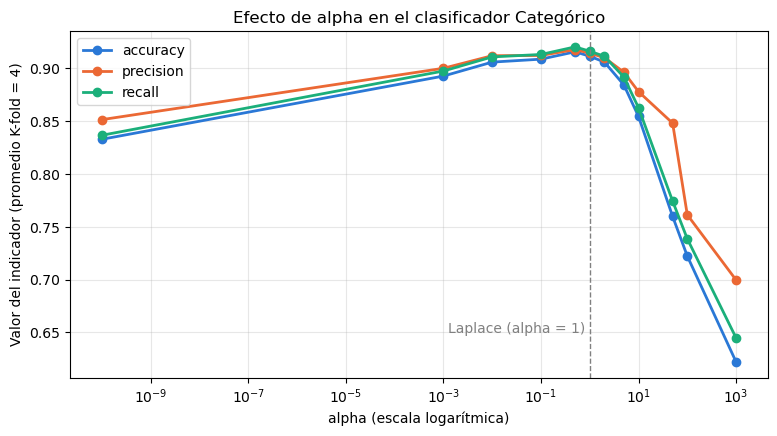

In [8]:
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(efecto_alpha['alpha'], efecto_alpha['accuracy (K-fold)'], marker='o', linewidth=2, color='#2a78d6', label='accuracy')
ax.plot(efecto_alpha['alpha'], efecto_alpha['precision (K-fold)'], marker='o', linewidth=2, color='#eb6834', label='precision')
ax.plot(efecto_alpha['alpha'], efecto_alpha['recall (K-fold)'], marker='o', linewidth=2, color='#1baf7a', label='recall')
ax.axvline(1, color='gray', linestyle='--', linewidth=1)
ax.text(0.8, 0.65, 'Laplace (alpha = 1)', color='gray', ha='right')
ax.set_xscale('log')
ax.set_xlabel("alpha (escala logarítmica)")
ax.set_ylabel("Valor del indicador (promedio K-fold = 4)")
ax.set_title("Efecto de alpha en el clasificador Categórico")
ax.grid(alpha=0.3)
ax.legend()
plt.show()

### Efecto de $\alpha$

* **$\alpha$ muy pequeño ($10^{-10}$):** accuracy de 0.8330. Los valores que no aparecen en el entrenamiento tienen probabilidad 0 y descartan a la clase correcta.
* **$\alpha$ entre 0.01 y 2:** mejores resultados, porque se eliminan los ceros. El máximo está en $\alpha = 0.5$ (0.9158), y $\alpha = 1$ queda muy cerca (0.9116).
* **$\alpha$ grande (5 o más):** el accuracy baja hasta 0.6221 con $\alpha = 1000$, porque todas las probabilidades se acercan a $\frac{1}{17}$ y los píxeles dejan de diferenciar las clases. El recall cae más rápido que la precision, porque el clasificador deja de predecir algunos dígitos (con $\alpha = 1000$ nunca predice el 8 en los datos de prueba).

Los valores son de K-fold. Los datos de prueba siguen el mismo patrón.

**Conclusión:** el Suavizado de Laplace ($\alpha = 1$) está en el rango con los mejores indicadores.